## ENEM: KNN


O método KNN de `statstech` prevê a nota média a partir dos participantes mais próximos. são realizados testes com diferentes números de vizinhos (k) e comparar o RMSE por validação cruzada.

### 0. Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from statstech.neighbors import KNeighborsRegressor
from statstech.model_selection import GridSearchCV, KFold
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED
from analysis.io import load_dataset
from analysis.report import save_figure, save_table

### 1. Dados

In [ ]:
d = load_dataset("enem")

X_train = d["X_train"]
y_train = d["y_train"]

feature_names = d["feature_names"]

print(f"Dados de treino: {X_train.shape[0]} participantes, {X_train.shape[1]} colunas")


Dados de treino: 38347 participantes, 41 colunas


In [4]:
cols_continues = [8, 9, 40]

### 2. Validação cruzada

Usamos validação cruzada com 5 folds. Em cada execuçõ, parte dos dados sõ utilizadas para teste, enquanto as demais são utilizadas para treinar o modelo. 

In [5]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

### 3. Seleção de uma amostra de treinamento

Para reduzir o custo computacional da busca dos hiperparâmetros, utiliamos uma subamostra de 20.000 observações do conjunto de treinamento se a base ultrapassar esse limite. A seleção e realizada de modo aleatório, sem reposição, utilizando uma semente fixa para garantir a reprodutibilidade dos resultados. 

In [6]:
sample_size = 20000

rng = np.random.default_rng(SEED)

if len(X_train) > sample_size:
    indices = rng.choice(
        len(X_train),
        size=sample_size,
        replace=False
    )

    X_knn = X_train[indices]
    y_knn = y_train[indices]

    print("Busca utilizando uma subamostra de 20 mil observações")

else:
    X_knn = X_train
    y_knn = y_train

    print("Busca utilizando todo o conjunto de treino")

print("Dimensão da amostra:", X_knn.shape)

Busca utilizando uma subamostra de 20 mil observações
Dimensão da amostra: (20000, 41)


### 4. Construção dos modelos KNN

O modelo é treinado para diferentes valores para k, k = [5, 15, 31, 61, 121]. k representa o número de vizinhos mais próximos que o KNN considera para a previsão de um novo ponto. 

In [7]:
pipe_knn = Pipeline([
    ("scaler", StandardScaler(columns=cols_continues)),
    ("model", KNeighborsRegressor())
])

knn = GridSearchCV(
    pipe_knn,
    {"model__n_neighbors": [5, 15, 31, 61, 121]},
    cv=cv,
    scoring="rmse"
)

knn.fit(X_knn, y_knn)

GridSearchCV(cv=<statstech.model_selection.split.KFold object at 0x000001E9FE122FF0>, error_score=nan, estimator=Pipeline(steps=[('scaler', StandardScaler(columns=[8, 9, 40], with_mean=True, with_std=True)), ('model', KNeighborsRegressor(n_neighbors=5))]), param_grid={'model__n_neighbors': [5, 15, 31, 61, 121]}, refit=True, scoring='rmse')

A busca com `GridSearchCV`, encontra o modelo que apresenta o menor RMSE durante a validação cruzada

### 5. Identificação dos resultados

Identifica os dados do modelo de melhor desempenho

In [8]:
best_model = knn.best_estimator_

best_k =knn.best_params_["model__n_neighbors"]

best_rmse = knn.best_score_

print("Melhor valor de K:", best_k)
print(f"Melhor RMSE médio: {best_rmse:.4f}")

Melhor valor de K: 121
Melhor RMSE médio: 74.3837


Os resultados evidenciam que a quantidade de vizinhos influencia o desempenho do modelo, de modo a alterar o nível de variação e a capacidade de adptação do KNN aos dados

### 6. Resultados ordenados dos  por k

Apresenta os valores de k e RMSE obtidos em cada modelo. 


In [9]:
results_knn = []

for result in knn.cv_results_:

    results_knn.append({
        "k": result["params"]["model__n_neighbors"], 
        "RMSE": result["mean_score"],
        "desvio": result["std_score"]
    })

results_knn = sorted(
    results_knn,
    key=lambda x: x["k"]
)

for result in results_knn:
    print(
        f"k = {result["k"]:3d} | "
        f"RMSE = {result["RMSE"]:.4f}"
    )

k =   5 | RMSE = 79.8182
k =  15 | RMSE = 75.6456
k =  31 | RMSE = 74.6824
k =  61 | RMSE = 74.4229
k = 121 | RMSE = 74.3837


### 7. Gráfico RMSE x k

O gráfico apresenta a variação de RMSE médio para os diferentes valores de k investigados. O menor valor da curva representa o modelo com melhor desempenho na validação cruzada. 

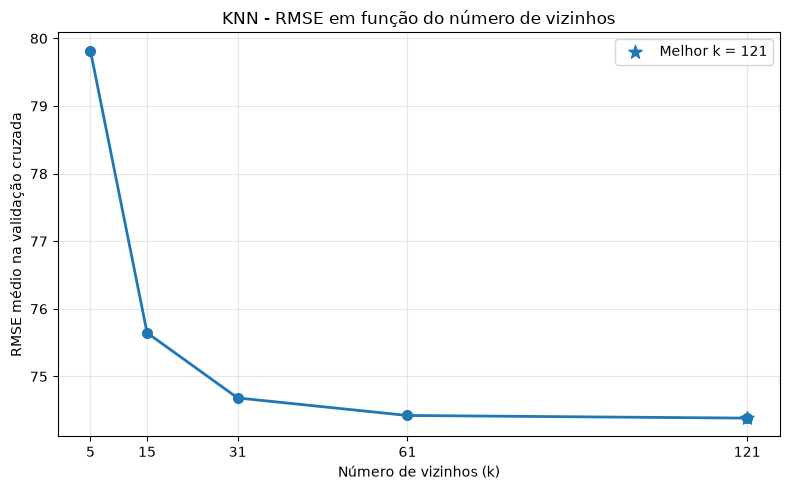

In [10]:
ks = [r["k"] for r in results_knn]
rmses = [r["RMSE"] for r in results_knn]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    ks, 
    rmses,
    marker="o",
    linewidth=2,
    markersize=7
)

ax.scatter(
    best_k,
    best_rmse,
    s=100,
    marker="*",
    label=f"Melhor k = {best_k}"
)

ax.set_title("KNN - RMSE em função do número de vizinhos")
ax.set_xlabel("Número de vizinhos (k)")
ax.set_ylabel("RMSE médio na validação cruzada")

ax.set_xticks(ks)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

save_figure(fig, "enem_knn_rmse")

plt.show()

Essa visualização permite obervar como o aumento de k influencia o erro de previsão e auxilia a identificar o melhor hiperparâmetro.

### 8. Treinamento do modelo final

Após identificar o melhor valor de k, ajustamos o modelo utilizando todo o conjunto de treinamento, aproveitando todas as observações diponíveis para construir o modelo final.

In [11]:
final_model  = Pipeline([
    ("scaler", StandardScaler(columns=cols_continues)),
    ("model", KNeighborsRegressor(n_neighbors=best_k))
    ])

final_model.fit(X_train, y_train)

print("Modelo KNN ajustado no treino completo.")
print("Melhor k:", best_k)

Modelo KNN ajustado no treino completo.
Melhor k: 121


In [12]:
save_table(
    results_knn, 
    "enem_knn_cv"
)

WindowsPath('C:/Users/lucas/statstech-analise/results/tables/enem_knn_cv.csv')

### 9. Conclusão


Os resultados demonstram que o aumento do número de vizinhos contribuiu para a redução do erro de previsão do modelo KNN. O menor RMSE médio foi obtido com k=121, alcançando 74,3837 pontos. Entretanto, observa-se que a redução do erro se torna progressivamente menor conforme k aumenta, sugerindo uma estabilização do desempenho do modelo. Assim, entre os valores investigados, k==121 apresentou o melhor resultado. Os resultados também sugerem que a utilização de um número maior de vizinhos favorece a generalização do modelo nesta base de dados, reduzindo a influência de observações inviduais sobre as previsões.